# 分组处理

分组聚合是数据分析里最常用的操作：销售额按地区汇总、日志按小时计数、实验数据按组求均值，本质都是「先分组，再对每组算一个数」。Polars 把这件事拆成两个动作，再配上一组变体，覆盖了绝大多数场景。

- `group_by` — 按列的值分组
- `agg` — 每组算出一个结果
- `having` — 用聚合结果反过来筛组
- `over` — 把每组的计算结果放回原来的行
- `group_by_dynamic` / `rolling` — 按时间轴或行号的窗口聚合

它们共用同一个「分组 → 聚合」框架，区别只在于结果是合成 1 行，还是分发回原来的行。

In [1]:
import polars as pl
from helper.jupyter import row

## group_by

`DataFrame.group_by()` 返回一个分组对象（`GroupBy`），这时还没有真正计算，只是记下了「按哪些列分」。

指定 `maintain_order=True` 可以让组的顺序保持数据中出现的顺序；默认不保证顺序，因为底层会并行处理各分组。

In [2]:
df = pl.DataFrame(
    dict(
        g=['A', 'B', 'C', 'A', 'B', 'B'], 
        x=[1, 2, 3, 4, 5, 6])
)
g = df.group_by('g', maintain_order=True)
type(g)

polars.dataframe.group_by.GroupBy

### 用 agg 聚合

把表达式传给 `GroupBy.agg()`，就按组计算并把每组压成 1 行。

常用的聚合也有 `GroupBy` 的方法形式（`.mean()`、`.first()` 等），本质是 `agg()` 写同样表达式的语法糖，结果完全一样；需要同时算好几个量时，还是 `agg()` 更省事。

In [3]:
row(
    g.mean(), 
    g.agg(pl.all().mean()),
    g.first(),
    g.agg(pl.all().first())
)

g,x
str,f64
"""A""",2.5
"""B""",4.333333
"""C""",3.0
g,x
str,f64
"""A""",2.5
"""B""",4.333333
"""C""",3.0
g,x


`agg()` 里如果用返回多个值的表达式（比如 `head(2)`），结果列会是列表，因为一个组对应多行。

想得到 `GroupBy.head()` 那种「组还是多行」的形状，用 `explode()` 把列表竖着展开就行。

In [4]:
row(
    g.head(2), 
    g.agg(pl.all().head(2)), 
    g.agg(pl.all().head(2)).explode('x')
)

g,x
str,i64
"""A""",1
"""A""",4
"""B""",2
"""B""",5
"""C""",3
g,x
str,list[i64]
"""A""","[1, 4]"
"""B""","[2, 5]"


在 `agg()` 里用 `map_batches()` 调用用户函数的情况，见[在 GroupBy.agg() 里使用 map_batches()](map_batches_in_agg)。

### 用 having 筛组

聚合之后，常有「只保留满足某个条件的组」的需求，比如「订单数超过 10 的客户」「平均分低于 60 的班级」。SQL 里这叫 `HAVING`，Polars 对应 `GroupBy.having()`。

- 参数是含聚合表达式的条件，写法和平时的 `filter()` 一样
- 返回值还是 `GroupBy`，所以可以接着写 `agg()` 或 `mean()`

下面的例子里先数每组的件数，把只有 1 件的 `C` 去掉，再算平均。

In [5]:
g.having(pl.col('g').count() > 1).mean()

g,x
str,f64
"""A""",2.5
"""B""",4.333333


`having()` 和 `filter()` 的区别在于对象是行还是组：前者看的是「这一组的统计量」，后者看的是「这一行自己的值」。

| 方法       | 筛选对象    |
|------------|-------------|
| `filter()` | 行（row）   |
| `having()` | 组（group） |

(over)=
## over

在表达式里用 `.over()`，可以把按组算出的结果分发回原来的行，行数不变。

下面的代码按 `g` 算 `x` 的平均值，并把这个值填到组内每一行；`group_by().agg()` 是一组一行，`over()` 则是「一组一个值，广播到全组」。

In [6]:
df.with_columns(
    pl.col('x').mean()
    .over('g').alias('x_mean')
)

g,x,x_mean
str,i64,f64
"""A""",1,2.5
"""B""",2,4.333333
"""C""",3,3.0
"""A""",4,2.5
"""B""",5,4.333333
"""B""",6,4.333333


下面的代码按 `g` 分组算 `x` 的平均值，再用 `x` 减去平均值，结果放进新列 `x_sub_mean`。

这就是常说的「组内去均值」：每组的计算结果回到对应的行上，行数不变，后面可以继续用这一列做排序或过滤。

In [7]:
df.with_columns(
    (pl.col('x') - pl.col('x').mean())
    .over('g')
    .alias('x_sub_mean')
)

g,x,x_sub_mean
str,i64,f64
"""A""",1,-1.5
"""B""",2,-2.333333
"""C""",3,0.0
"""A""",4,1.5
"""B""",5,0.666667
"""B""",6,1.666667


如果每组的结果长度既不是 1，也不等于原行数（比如 `.head(2)`），直接写会报错，因为 Polars 不知道该把多出来的值放到哪里。

指定 `mapping_strategy='join'` 就能把结果作为列表放进原来的行；下面的例子把每组前 2 条收成列表放进新列。

In [8]:
df.with_columns(
    pl.col('x').head(2)
    .over('g', mapping_strategy='join')
    .alias('x_head')
)

g,x,x_head
str,i64,list[i64]
"""A""",1,"[1, 4]"
"""B""",2,"[2, 5]"
"""C""",3,[3]
"""A""",4,"[1, 4]"
"""B""",5,"[2, 5]"
"""B""",6,"[2, 5]"


下面的代码按 `g` 分组取 `x` 的最小值和最大值，把两个值作为列表放进新列。

`append()` 在表达式里用来把两个标量拼成一个长度 2 的列表，正好配合 `mapping_strategy='join'`。

In [9]:
df.with_columns(
    pl.col('x').min().append(pl.col('x').max())
    .over('g', mapping_strategy='join')
    .alias('x_min_max')
)

g,x,x_min_max
str,i64,list[i64]
"""A""",1,"[1, 4]"
"""B""",2,"[2, 6]"
"""C""",3,"[3, 3]"
"""A""",4,"[1, 4]"
"""B""",5,"[2, 6]"
"""B""",6,"[2, 6]"


`mapping_strategy='explode'` 会把每组的结果竖着排开，效果和 `group_by().agg().explode()` 一样，但省掉了先聚合再展开两步。

它适合「每个组要展开成若干行，但不想改变列结构」的场景。

In [10]:
df.select(
    pl.col('g', 'x').head(2)
    .over('g', mapping_strategy='explode')
)

g,x
str,i64
"""A""",1
"""A""",4
"""B""",2
"""B""",5
"""C""",3


`filter()` 里也能用 `over()` 的表达式，条件是「这一行和它所在组的统计量比较」。

下面的代码按 `g` 分组，保留 `x` 不小于该组平均值的行——这类「保留组内高于均值」的筛选，用窗口函数比先聚合再连接简单得多。

In [11]:
df.filter(
    (pl.col('x') >= pl.col('x').mean())
    .over('g')
)

g,x
str,i64
"""C""",3
"""A""",4
"""B""",5
"""B""",6


## group_by_dynamic

`group_by_dynamic(index)` 按 `index` 列的值做时间窗口分组，是时序降采样的主力函数。

第一组的起点 `start` 由 `start_by`、`every`、`offset` 和 `index` 的第一个值 `value` 决定。`start_by='window'`（默认）时按下式计算：

```
start = value - (value - offset) % every
```

这个式子的意思是：把时间轴按 `every` 切成固定的格子，然后让第一个值落进某个格子里。`start_by='datapoint'` 则不同，`start` 就是第一个值本身，格子从数据起点开始排。

起点定了之后，各组范围依次如下。`period` 的默认值和 `every` 相同。

```
[start, start + period)
[start + every, start + every + period)
...
[start + i * every, start + i * every + period)
```

组的起始值就是键。指定 `include_boundaries=True` 会多出 `_lower_boundary` 和 `_upper_boundary` 两列，能看出每组的开始（含）和结束（不含）——排查「为什么这一行没进组」时很有用。

下面的例子把 `index` 的值每 3 个单位并成一组聚合。

In [12]:
index = [1, 2, 4, 5, 6, 8, 9, 10, 11]
# 先把 index 升序排好（set_sorted 声明已排序）
df = pl.DataFrame(dict(index=index, value=list(range(len(index))))).set_sorted("index")

g = df.group_by_dynamic("index", every="3i", offset="0i", include_boundaries=True)
row(df, g.agg(pl.col("index").alias("index_in_group")))

index,value
i64,i64
1,0
2,1
4,2
5,3
6,4
8,5
9,6
10,7
11,8


为了便于用眼睛确认，本书用 `plot_group_by_dynamic()` 把组的边界画出来：蓝线是 `index` 的值，红线是组的键，绿块是每组的范围。

[[1, 2], [4, 5], [6, 8], [9, 10, 11]]


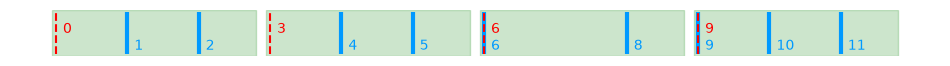

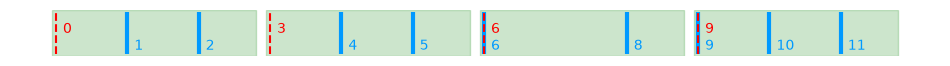

In [13]:
from helper import utils
from helper.utils import plot_group_by_dynamic
from matplotlib import pyplot as plt
plt.ioff()
plot_group_by_dynamic(index, every='3i', offset='0i')

下面输出 `offset` 参数影响的三张图，可以看到格子整体往后挪。

[[1, 2], [4, 5, 6], [8, 9], [10, 11]]


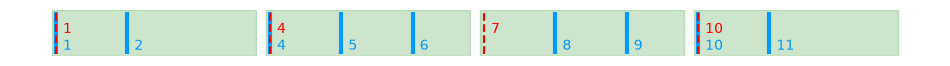

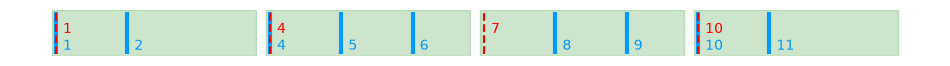

In [14]:
plot_group_by_dynamic(index, every='3i', offset='1i')

[[1], [2, 4], [5, 6], [8, 9, 10], [11]]


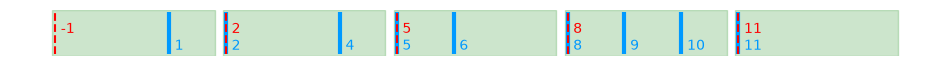

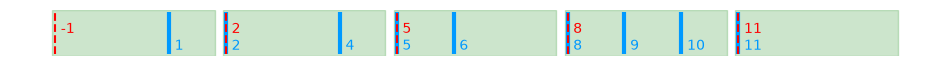

In [15]:
plot_group_by_dynamic(index, every='3i', offset='2i')

[[1], [2, 4], [5, 6], [8, 9, 10], [11]]


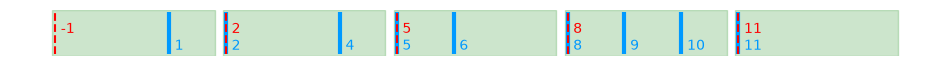

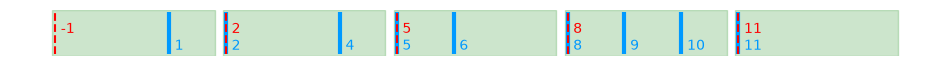

In [16]:
plot_group_by_dynamic(index, every='3i', offset='-1i')

`start_by='datapoint'` 时，第一组的起点固定成 `index` 的第一个值，所以 `offset` 不起作用——数据从哪儿开始，格子就从哪儿开始排。

[[1, 2], [4, 5, 6], [8, 9], [10, 11]]


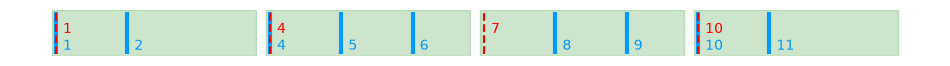

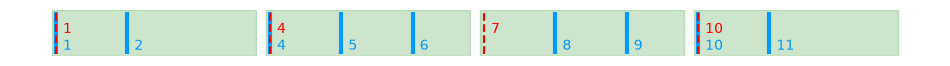

In [17]:
plot_group_by_dynamic(index, every='3i', start_by='datapoint')

`period` 的默认值和 `every` 相同，所以组之间不重叠，每条记录只属于一个组。

`period` 比 `every` 大时窗口会重叠，同一个 `index` 会落进多个组，适合做「滑动平均」式的统计。

[[1, 2, 4], [4, 5, 6], [6, 8, 9, 10], [9, 10, 11]]


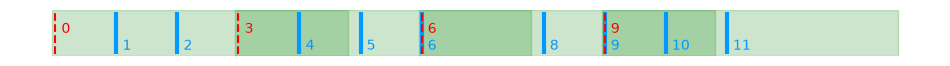

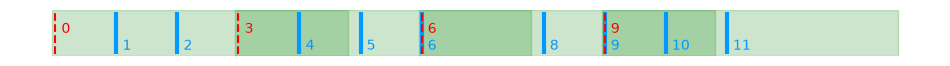

In [18]:
plot_group_by_dynamic(index, every='3i', period='5i')

下面的代码按 `index` 每次移动 1 个单位，每 3 个单位成一组：每行都会开启一个新窗口，窗口长度 3。

In [19]:
g = df.group_by_dynamic('index', every='1i', period='3i', include_boundaries=True)
row(df, g.agg(pl.col("index").alias('index_in_group')))

index,value
i64,i64
1,0
2,1
4,2
5,3
6,4
8,5
9,6
10,7
11,8


这里用整数列讲，实际更多用在时间序列上。`every`、`period`、`offset` 支持下面这些单位。

- `1ns`（纳秒）、`1us`（微秒）、`1ms`（毫秒）
- `1s`（秒）、`1m`（分）、`1h`（小时）
- `1d`（天）、`1w`（周）、`1mo`（月）、`1q`（季度）、`1y`（年）

## rolling

`rolling(index)` 按 `index` 列的值造滚动窗口，和 `group_by_dynamic` 的区别是它不做分组、也不降采样，而是对每一行给出「往前（或往后）看一段」的窗口。

`period` 和 `offset` 调整窗口位置，`offset` 的默认值是 `-period`，也就是默认往过去看。窗口范围 `()` 一侧不含，`[]` 一侧含。

```
(index[0] + offset, index[0] + offset + period]
...
(index[i] + offset, index[i] + offset + period]
```

下面的例子用包含前 2 个点的 3 点窗口聚合。

In [20]:
g = df.rolling('index', period='3i')
g.agg(pl.col("value"))

index,value
i64,list[i64]
1,[0]
2,"[0, 1]"
4,"[1, 2]"
5,"[2, 3]"
6,"[2, 3, 4]"
8,"[4, 5]"
9,"[5, 6]"
10,"[5, 6, 7]"
11,"[6, 7, 8]"


下面的代码按 `index` 造窗口，包含每个点之后的 2 个点，共 3 个点——把 `offset` 拨到正方向，窗口就朝未来看。

In [21]:
g = df.rolling('index', period='3i', offset='-1i')
g.agg(pl.col("value"))

index,value
i64,list[i64]
1,"[0, 1]"
2,"[1, 2]"
4,"[2, 3, 4]"
5,"[3, 4]"
6,"[4, 5]"
8,"[5, 6, 7]"
9,"[6, 7, 8]"
10,"[7, 8]"
11,[8]


想按固定行数开窗，就用 `int_range()` 造一列行号，再交给 `rolling()`。

下面的代码用「前 2 行 + 本行」共 3 行的窗口，算 `A` 的最大值和 `B` 的最小值；窗口按行数而不是按值走，所以不必关心 `index` 的间隔是否均匀。

In [22]:
df = pl.DataFrame(
    dict(
        A=[5, 3, 8, 9, 10, 1, 2, 4],
        B=[10, 20, 10, 2, 3, 5, 0, 7]
    )
)

(
    df
    .rolling(
        pl.int_range(0, pl.len()).alias('index'), 
        period='3i', 
        offset='-2i'
    )
    .agg(
        pl.col.A,
        pl.col.B,
        pl.col.A.max().alias('A_max'),
        pl.col.B.min().alias('B_min'),
    )
)

index,A,B,A_max,B_min
i64,list[i64],list[i64],i64,i64
0,"[5, 3]","[10, 20]",5,10
1,"[5, 3, 8]","[10, 20, 10]",8,10
2,"[3, 8, 9]","[20, 10, 2]",9,2
3,"[8, 9, 10]","[10, 2, 3]",10,2
4,"[9, 10, 1]","[2, 3, 5]",10,2
5,"[10, 1, 2]","[3, 5, 0]",10,0
6,"[1, 2, 4]","[5, 0, 7]",4,0
7,"[2, 4]","[0, 7]",4,0


也有 `Expr.rolling()`。参数和 `DataFrame.rolling()` 一样，但写在列上更灵活：它挂在表达式后面，窗口作用在那个表达式的结果上。

In [23]:
df.with_row_index().select(
    pl.col('A').rolling('index', period='3i', offset='-2i'),
    pl.col('A').max().rolling('index', period='3i', offset='-2i').alias('A_max')
)

A,A_max
list[i64],i64
"[5, 3]",5
"[5, 3, 8]",8
"[3, 8, 9]",9
"[8, 9, 10]",10
"[9, 10, 1]",10
"[10, 1, 2]",10
"[1, 2, 4]",4
"[2, 4]",4


注意 `.rolling()` 作用于**它前面整条表达式**，而不仅仅是最后那个函数。

1. **`pl.col('A').diff().max().rolling(...)`**（❶）— 先把 `A` 切进窗口，再在每个窗口内算 `.diff().max()`，也就是「窗口内的最大差分」。
2. **先算差分再开窗**（❷）— 先把 `dA = pl.col('A').diff()` 做成新列，再对它套 `.max().rolling(...)`，得到的是「差分序列的窗口最大值」。

两者结果不同，写之前想清楚要哪一个。

In [24]:
df1 = df.select('A').with_row_index().with_columns(
    pl.col('A').rolling('index', period='3i'),
    pl.col('A').diff().rolling('index', period='3i').alias('dA_rolling'),
    pl.col('A').diff().max().rolling('index', period='3i').alias('dA_max_rolling') #❶
)

df2 = df.select('A').with_row_index().with_columns(
    pl.col('A').diff().alias('dA') #❷
).with_columns(
    pl.col('dA').rolling('index', period='3i').alias('dA_rolling'),
    pl.col('dA').max().rolling('index', period='3i').alias('dA_max_rolling') #❷
)

row(df1, df2)

shape: (8, 4) index A dA_rolling dA_max_rolling u32 list[i64] list[i64] i64 0 [5] [null] null 1 [5, 3] [null, -2] -2 2 [5, 3, 8] [null, -2, 5] 5 3 [3, 8, 9] [null, 5, 1] 5 4 [8, 9, 10] [null, 1, 1] 1 5 [9, 10, 1] [null, 1, -9] 1 6 [10, 1, 2] [null, -9, 1] 1 7 [1, 2, 4] [null, 1, 2] 2 
 shape: (8, 5) index A dA dA_rolling dA_max_rolling u32 i64 i64 list[i64] i64 0 5 null [null] null 1 3 -2 [null, -2] -2 2 8 5 [null, -2, 5] 5 3 9 1 [-2, 5, 1] 5 4 10 1 [5, 1, 1] 5 5 1 -9 [1, 1, -9] 1 6 2 1 [1, -9, 1] 1 7 4 2 [-9, 1, 2] 2

## CookBook

### 按值的变化分组聚合

下面的代码在 `g` 的值每次变化时换一组，取每组的第一个 `g` 和 `v` 列的值。

`rle_id()` 给连续相同的值同一个编号，值一变就换号，正好把「连续的段」变成可以分组的键。

In [25]:
df = pl.DataFrame(
    {
        "g": [1, 1, 2, 2, 2, 1, 1, 0],
        "v": list(range(8))
    }
)

df.group_by(
    pl.col('g').rle_id().alias('group_id')
).agg(
    pl.col('g').first(),
    pl.col('v')
)

group_id,g,v
u32,i64,list[i64]
0,1,"[0, 1]"
1,2,"[2, 3, 4]"
2,1,"[5, 6]"
3,0,[7]


### 按组编号

给 `c1` 和 `c2` 的值组合编号，从 0 开始，出现新组合就加 1。这其实是「把复合键映射成整数 ID」，下面给出三种实现。

In [26]:
df = pl.DataFrame(
    {
        "c1": ["b", "a", "a", "b", "c", "a", "b"],
        "c2": [2, 1, 1, 1, 1, 1, 1],
    }
)

#### 用 group_by 计算

1. `group_by("c1", "c2", maintain_order=True)` — 按 `c1` 和 `c2` 的组合分组，并保持首次出现的顺序。
2. `agg(pl.col("row_index"))` — 把每行加的行号按组收成列表。Polars 2.0 删掉了 `agg_groups()`，所以先用 `with_row_index()` 造行号列再聚合。
3. `explode("row_index")` — 把列表展开成行。
4. `sort("row_index")` — 恢复原来的行序。
5. `drop("row_index")` — 去掉临时列。

In [27]:
(
    df.with_row_index("row_index")
    .group_by("c1", "c2", maintain_order=True)
    .agg(pl.col("row_index"))
    .explode("row_index")
    .sort("row_index")
    .drop("row_index")
)

c1,c2
str,i64
"""b""",2
"""a""",1
"""a""",1
"""b""",1
"""c""",1
"""a""",1
"""b""",1


#### 用 join 计算

用 `join` 也能得到同样的结果，思路是「先给唯一组合编好号，再按组合连回原表」。

1. `df.select('c1', 'c2')` — 只取 `c1` 和 `c2` 两列。
2. `unique(maintain_order=True)` — 取唯一的组合，保持出现顺序。
3. `with_row_index()` — 加行号，这个行号就是编号。
4. `df.join(..., on=["c1", "c2"])` — 把原表和带编号的唯一组合按两列连起来。

In [28]:
df.join(
    df.select('c1', 'c2')
    .unique(maintain_order=True)
    .with_row_index(),
    on=["c1", "c2"]
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2


#### 用类别型计算

把 `c1` 和 `c2` 的值拼成一个字符串，转成类别型（`Categorical`）再转成整数，也能得到同样的编号。

1. `pl.format("{} - {}", "c1", "c2")` — 拼成 `"a - 1"` 这样的字符串。
2. `cast(pl.Categorical)` — 转成类别型，内部会给每个不同值分配整数。
3. `to_physical()` — 取出类别对应的整数。
4. `alias("index")` — 给新列起名。

这种写法比 `join` 少一次连接，但编号顺序取决于类别出现的顺序，跨批次不一定稳定。

In [29]:
df.with_columns(
    pl.format("{} - {}", "c1", "c2")
    .cast(pl.Categorical)
    .to_physical()
    .alias("index")
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2


#### 用结构体和类别型计算

`pl.format()` 用不了时（比如列里有混合类型），也可以先把结构体列转成类别型。

1. `pl.struct("c1", "c2")` — 把两列合成一个结构体，作为一个整体处理。
2. `rank("dense")` — 按结构体做密集排名：同值同名次，名次不跳号。
3. `cast(pl.String)` — 排名是整数，不能直接转类别型，先转成字符串。

In [30]:
df.with_columns(
    pl.struct("c1", "c2")
    .rank("dense")
    .cast(pl.String)
    .cast(pl.Categorical)
    .to_physical()
    .alias("index")
)

c1,c2,index
str,i64,u32
"""b""",2,0
"""a""",1,1
"""a""",1,1
"""b""",1,2
"""c""",1,3
"""a""",1,1
"""b""",1,2
